# CLIP은 생성된 결함을 "균열"로 볼까

노드 8에서 AnomalyAny는 내부에서 CLIP(ViT-L/14)으로 "생성한 결함이 crack이라는 글과 맞는지" 점수를 매기며 그림을 밀었다.
그런데 사람 눈으로 보면 균열 모양은 4장 중 1장(커넥터)뿐이었다. CLIP의 눈에는 어떻게 보이는지 확인한다.

- 사진 6장: 0 원본 정상 PCB / 1~4 AnomalyAny 강사 출력 / 5 노드 8-1 Inpainting(crack 지시) 결과
- 문장 2개: "a photo of a normal printed circuit board" / "a photo of a printed circuit board with a crack"
- 모델 2개: AnomalyAny가 쓰는 ViT-L/14, 작은 ViT-B/32 (Hugging Face `openai/clip-vit-*`)
- 사진 전체 / 커넥터 부분만 잘라서 각각 넣는다. 학습 없이 추론만 한다(CPU).

**돌리기 전 내 예상**
1. 균열 확률이 가장 높은 사진은 1번(커넥터 균열)일 것 같다.
2. 1번은 통째로보다 커넥터만 잘라서 보여 주면 균열 확률이 더 높을 것 같다.
3. 사람 눈에는 균열이 아니었던 2·3·4번도 원본보다는 균열 확률이 높게 나올 것 같다.

In [1]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

plt.rcParams.update({'font.family': 'Malgun Gothic', 'axes.unicode_minus': False})

NAMES = {
    '0_original': '0 원본(정상)',
    '1_aa_connector_crack': '1 AA 커넥터 균열',
    '2_aa_part_changed': '2 AA 부품 바뀜',
    '3_aa_shape_changed': '3 AA 모양 바뀜',
    '4_aa_white_stain': '4 AA 흰 얼룩',
    '5_b1_inpaint': '5 Inpainting',
}
TEXTS = ['a photo of a normal printed circuit board',
         'a photo of a printed circuit board with a crack']
CONNECTOR = (110, 160, 230, 310)  # 512x512 기준 왼쪽 USB 커넥터 자리 (노드 8 비교 그림과 같은 상자)
images = {k: Image.open(f'images/{k}.png').convert('RGB') for k in NAMES}

In [2]:
def crack_prob(model, proc, image):
    """사진 1장 vs 문장 2개: 코사인 유사도 x 온도 -> softmax. 논문 Figure 1의 (3) 제로샷 분류와 같다."""
    inputs = proc(text=TEXTS, images=image, return_tensors='pt', padding=True)
    with torch.no_grad():
        logits = model(**inputs).logits_per_image[0]
    return logits.softmax(-1)[1].item()  # 'with a crack' 쪽 확률


rows = []
for mid in ['openai/clip-vit-base-patch32', 'openai/clip-vit-large-patch14']:
    model = CLIPModel.from_pretrained(mid).eval()
    proc = CLIPProcessor.from_pretrained(mid)
    for k, label in NAMES.items():
        img = images[k]
        rows.append({'model': mid.split('-', 2)[-1], 'image': label,
                     'whole': crack_prob(model, proc, img),
                     'connector': crack_prob(model, proc, img.crop(CONNECTOR))})
df = pd.DataFrame(rows)
print(df.pivot(index='image', columns='model', values=['whole', 'connector']).round(3))

                    whole                  connector              
model        base-patch32 large-patch14 base-patch32 large-patch14
image                                                             
0 원본(정상)            0.042         0.133        0.257         0.724
1 AA 커넥터 균열         0.057         0.649        0.370         0.799
2 AA 부품 바뀜          0.042         0.205        0.448         0.347
3 AA 모양 바뀜          0.050         0.195        0.250         0.501
4 AA 흰 얼룩           0.067         0.340        0.240         0.649
5 Inpainting        0.060         0.252        0.304         0.839


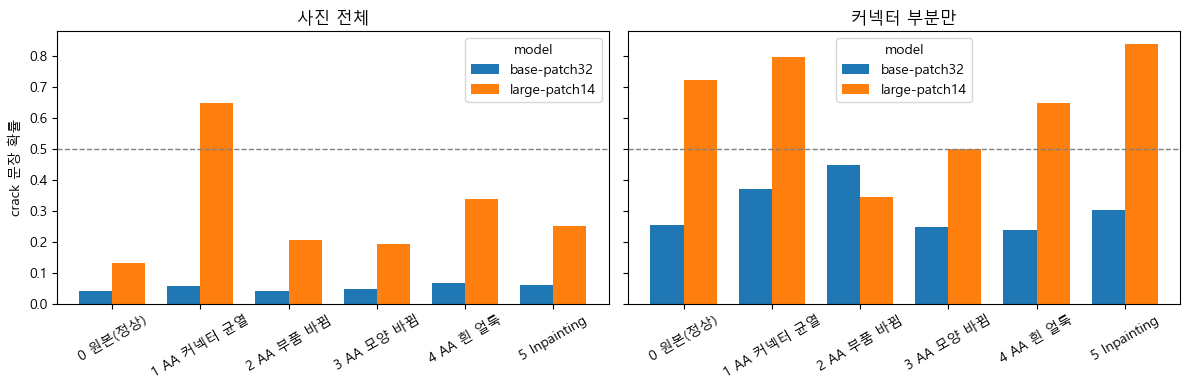

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col, title in zip(axs, ['whole', 'connector'], ['사진 전체', '커넥터 부분만']):
    p = df.pivot(index='image', columns='model', values=col)
    p.plot.bar(ax=ax, rot=30, width=0.75)
    ax.axhline(0.5, color='gray', lw=1, ls='--')
    ax.set_title(title)
    ax.set_ylabel('crack 문장 확률')
    ax.set_xlabel('')
plt.tight_layout()
plt.savefig('images/clip_crack_prob.png', dpi=150)
plt.show()

## 결과

crack 문장 확률 (위 표, 0.5 넘으면 "균열"로 판정)

| 사진 | ViT-B/32 전체 | ViT-L/14 전체 | ViT-L/14 커넥터만 |
| --- | ---: | ---: | ---: |
| 0 원본(정상) | 0.042 | 0.133 | 0.724 |
| 1 AA 커넥터 균열 | 0.057 | **0.649** | 0.799 |
| 2 AA 부품 바뀜 | 0.042 | 0.205 | 0.347 |
| 3 AA 모양 바뀜 | 0.050 | 0.195 | 0.501 |
| 4 AA 흰 얼룩 | 0.067 | 0.340 | 0.649 |
| 5 Inpainting | 0.060 | 0.252 | 0.839 |

**예상과 비교**
1. 균열 확률 최고는 1번 → 맞음. ViT-L/14로 전체를 보면 1번만 0.5를 넘었다(0.649). 사람 눈과 같은 판단이다.
2. 커넥터만 자르면 더 높다 → 숫자는 맞았지만(0.649 → 0.799), 진짜 정상인 0번 커넥터도 0.724가 나왔다. 잘라 낸 사진이면 무엇이든 균열 쪽으로 기우는 것이라 구분이 나아진 게 아니다. 균열이 없는 5번이 0.839로 가장 높다.
3. 2·3·4번도 원본보다 높다 → 맞음. 0.195~0.340으로 모두 원본(0.133)보다 높다.

**처음 해석** (아래 확인에서 일부 고침)
- 작은 모델(ViT-B/32)은 사진 전체에서 6장 모두 0.04~0.07로, 아무것도 구분하지 못했다. 큰 모델만 1번의 균열을 알아봤다.
- 커넥터 확대 사진에서 정상도 균열로 본 건, 처음엔 4억 장 안에 PCB 커넥터 확대 사진이 없었기 때문이라고 생각했다. 아래 확인 A~D에서 이 해석은 고쳤다(원인은 문장과 유사도 차이 쪽이었다).
- AnomalyAny는 이 ViT-L/14 점수를 보며 crack을 밀어 넣는다. 그런데 균열이 아닌 2·3·4번도 원본보다 점수가 높았다. CLIP 점수는 "균열인가"보다 "뭔가 이상해 보이는가"에 반응하는 것 같고, 그래서 AnomalyAny가 crack을 밀었을 때 균열 대신 부품이 바뀌거나 얼룩이 생겨도 점수가 오른다. 생성한 결함을 CLIP 점수만으로 검증하면 안 되는 이유다.

**한계**: 사진 6장, 문장 1쌍, 1번만 돌렸다. 1~4번은 강사가 남긴 출력이라 다시 만들 수 없다. 5번은 노드 8 노트북 출력 그림에서 잘라 낸 것이라 해상도가 낮다.

## 결과를 믿어도 되나: 확인 A · B · C

위 결과를 보고 두 가지가 의심스러웠다.
- 모델이 제대로 작동하는 상태인지 먼저 확인하지 않았다.
- 커넥터만 잘라 낸 사진은 PCB처럼 보이지 않는데, 문장은 "정상 PCB" / "균열 PCB" 둘뿐이었다. 둘 다 안 맞으면 CLIP은 덜 안 맞는 쪽을 고를 수밖에 없어서, 0.724가 "균열로 봤다"가 아니라 문장을 잘못 준 탓일 수 있다.

그래서 세 가지를 확인한다.
- **A. 작동 확인**: 원본 사진과 커넥터 확대 사진이 무엇인지 여러 물체 이름 중에서 고르게 한다.
- **B. 대상에 맞는 문장**: 커넥터 사진에는 "정상 USB 커넥터" / "금 간 USB 커넥터"로 묻는다. 논문 3.1.4장의 prompt engineering(문장을 대상에 맞게 써야 한다)과 같은 이야기다.
- **C. 문장 여러 쌍**: 같은 뜻의 문장 쌍 4개로 결과가 얼마나 흔들리는지 본다.

돌리기 전 내 예상(B): 커넥터에 맞는 문장으로 바꾸면 0번 원본 커넥터의 균열 확률은 오히려 올라갈 것 같다.

In [4]:
def probs(model, proc, image, texts):
    inputs = proc(text=texts, images=image, return_tensors='pt', padding=True)
    with torch.no_grad():
        return model(**inputs).logits_per_image[0].softmax(-1).tolist()


model = CLIPModel.from_pretrained('openai/clip-vit-large-patch14').eval()
proc = CLIPProcessor.from_pretrained('openai/clip-vit-large-patch14')

# A. 작동 확인: 무엇이 찍힌 사진인지 고르게 한다
OBJECTS = ['a printed circuit board', 'a USB connector', 'a dog', 'a car', 'a banana']
A = {}
for k in ['0_original', '1_aa_connector_crack']:
    for part, img in [('전체', images[k]), ('커넥터', images[k].crop(CONNECTOR))]:
        p = probs(model, proc, img, [f'a photo of {o}' for o in OBJECTS])
        A[f'{NAMES[k]} / {part}'] = dict(zip(OBJECTS, p))
print('[A] 무엇이 찍혔나 (ViT-L/14)')
print(pd.DataFrame(A).T.round(3))

[A] 무엇이 찍혔나 (ViT-L/14)
                   a printed circuit board  a USB connector  a dog  a car  \
0 원본(정상) / 전체                        0.092            0.908    0.0    0.0   
0 원본(정상) / 커넥터                       0.087            0.913    0.0    0.0   
1 AA 커넥터 균열 / 전체                     0.951            0.049    0.0    0.0   
1 AA 커넥터 균열 / 커넥터                    0.461            0.539    0.0    0.0   

                   a banana  
0 원본(정상) / 전체           0.0  
0 원본(정상) / 커넥터          0.0  
1 AA 커넥터 균열 / 전체        0.0  
1 AA 커넥터 균열 / 커넥터       0.0  


In [5]:
# B, C. 문장 쌍을 바꿔 가며 crack 쪽 확률
PAIRS = {
    'PCB 문장 (처음 실험)': ('a photo of a normal printed circuit board', 'a photo of a printed circuit board with a crack'),
    '커넥터 문장 1': ('a photo of a normal metal USB connector', 'a photo of a cracked metal USB connector'),
    '커넥터 문장 2': ('a close-up photo of an intact USB connector', 'a close-up photo of a broken USB connector'),
    '커넥터 문장 3': ('a USB port in good condition', 'a damaged USB port with a crack'),
}
rows = []
for k, label in NAMES.items():
    for part, img in [('전체', images[k]), ('커넥터', images[k].crop(CONNECTOR))]:
        for pname, (ok, bad) in PAIRS.items():
            rows.append({'image': label, 'part': part, 'pair': pname, 'crack': probs(model, proc, img, [ok, bad])[1]})
dfB = pd.DataFrame(rows)
print('[B·C] 커넥터 부분, 문장 쌍별 crack 확률 (ViT-L/14)')
print(dfB[dfB.part == '커넥터'].pivot(index='image', columns='pair', values='crack').round(3))
print()
print('[참고] 사진 전체, 문장 쌍별')
print(dfB[dfB.part == '전체'].pivot(index='image', columns='pair', values='crack').round(3))

[B·C] 커넥터 부분, 문장 쌍별 crack 확률 (ViT-L/14)
pair          PCB 문장 (처음 실험)  커넥터 문장 1  커넥터 문장 2  커넥터 문장 3
image                                                     
0 원본(정상)               0.724     0.551     0.774     0.959
1 AA 커넥터 균열            0.799     0.868     0.704     0.944
2 AA 부품 바뀜             0.347     0.730     0.676     0.832
3 AA 모양 바뀜             0.501     0.481     0.697     0.775
4 AA 흰 얼룩              0.649     0.514     0.625     0.785
5 Inpainting           0.839     0.791     0.768     0.983

[참고] 사진 전체, 문장 쌍별
pair          PCB 문장 (처음 실험)  커넥터 문장 1  커넥터 문장 2  커넥터 문장 3
image                                                     
0 원본(정상)               0.133     0.093     0.682     0.268
1 AA 커넥터 균열            0.649     0.679     0.544     0.269
2 AA 부품 바뀜             0.205     0.188     0.779     0.238
3 AA 모양 바뀜             0.195     0.208     0.697     0.314
4 AA 흰 얼룩              0.340     0.439     0.730     0.488
5 Inpainting           0.252     0.186     0.759     0.3

## 성능을 올려 보기: 실험 D

- **D1. 유사도 원래 값**: CLIP 확률은 코사인 유사도에 100(학습된 온도)을 곱해 softmax한 것이다. 확률 0.724는 거꾸로 계산하면 유사도 차이 0.0096밖에 안 된다. 원래 값을 직접 본다.
- **D2. 문장 앙상블**: 문장 틀 5개 × 정상 표현 4개 / 균열 표현 4개의 텍스트 임베딩을 평균 낸다 (논문 3.1.4장).
- **D3. 정상 사진과 비교**: 글 대신 원본 정상 사진의 CLIP 이미지 특징과 얼마나 다른지(1 − 코사인 유사도)를 잰다. 노드 6 PaDiM처럼 사진을 4×4 = 16칸으로 나눠 칸마다 같은 자리의 원본 칸과 비교하고, 가장 다른 칸(max)을 사진 점수로 쓴다. 정상 사진은 원본 1장뿐이라 원본 자신은 0이 되므로 1~5번끼리 비교한다.

돌리기 전 내 예상
- D1: 원본 커넥터에서 두 문장의 유사도 차이는 클 것 같다.
- D2: 평균을 내면 더 흔들릴 것 같고, 1번이 더 높아질지는 모르겠다.
- D3: 1번이 정상과 가장 다르게 나올 것 같다.

In [6]:
import numpy as np


@torch.no_grad()
def text_emb(texts):
    t = proc(text=texts, return_tensors='pt', padding=True)
    e = model.text_projection(model.text_model(**t).pooler_output)  # CLIPModel.forward와 같은 경로
    return e / e.norm(dim=-1, keepdim=True)


@torch.no_grad()
def img_emb(imgs):
    x = proc(images=imgs, return_tensors='pt')
    e = model.visual_projection(model.vision_model(pixel_values=x['pixel_values']).pooler_output)
    return e / e.norm(dim=-1, keepdim=True)


SCALE = model.logit_scale.exp().item()
print(f'온도 값(logit_scale) = {SCALE:.1f}')

# D1: PCB 문장 쌍의 유사도 원래 값
pair = text_emb(list(PAIRS['PCB 문장 (처음 실험)']))
rows = []
for k, label in NAMES.items():
    for part, img in [('전체', images[k]), ('커넥터', images[k].crop(CONNECTOR))]:
        s = (img_emb([img]) @ pair.T)[0]
        rows.append({'image': label, 'part': part, 'sim_normal': s[0].item(), 'sim_crack': s[1].item(),
                     'gap': (s[1] - s[0]).item(), 'crack_prob': (s * SCALE).softmax(-1)[1].item()})
d1 = pd.DataFrame(rows)
print('[D1] 유사도 원래 값 (ViT-L/14, PCB 문장 쌍)')
print(d1.round(4).to_string(index=False))

온도 값(logit_scale) = 100.0


[D1] 유사도 원래 값 (ViT-L/14, PCB 문장 쌍)
       image part  sim_normal  sim_crack     gap  crack_prob
    0 원본(정상)   전체      0.2098     0.1910 -0.0187      0.1330
    0 원본(정상)  커넥터      0.2528     0.2625  0.0096      0.7238
 1 AA 커넥터 균열   전체      0.2277     0.2339  0.0061      0.6488
 1 AA 커넥터 균열  커넥터      0.2564     0.2702  0.0138      0.7991
  2 AA 부품 바뀜   전체      0.2228     0.2092 -0.0135      0.2051
  2 AA 부품 바뀜  커넥터      0.2693     0.2630 -0.0063      0.3467
  3 AA 모양 바뀜   전체      0.2252     0.2110 -0.0142      0.1953
  3 AA 모양 바뀜  커넥터      0.2693     0.2693  0.0001      0.5014
   4 AA 흰 얼룩   전체      0.2321     0.2255 -0.0067      0.3395
   4 AA 흰 얼룩  커넥터      0.2551     0.2612  0.0062      0.6491
5 Inpainting   전체      0.2178     0.2069 -0.0109      0.2519
5 Inpainting  커넥터      0.2398     0.2563  0.0165      0.8387


In [7]:
# D2: 문장 앙상블
TEMPLATES = ['a photo of a {}.', 'a close-up photo of a {}.', 'a cropped photo of a {}.',
             'a bright photo of a {}.', 'a photo of the {}.']
GOOD = ['normal', 'intact', 'undamaged', 'flawless']
BAD = ['cracked', 'broken', 'damaged', 'defective']


def ensemble(obj):
    good = text_emb([t.format(f'{w} {obj}') for t in TEMPLATES for w in GOOD]).mean(0)
    bad = text_emb([t.format(f'{w} {obj}') for t in TEMPLATES for w in BAD]).mean(0)
    e = torch.stack([good, bad])
    return e / e.norm(dim=-1, keepdim=True)


ENS = {'전체': ensemble('printed circuit board'), '커넥터': ensemble('USB connector')}
rows = []
for k, label in NAMES.items():
    for part, img in [('전체', images[k]), ('커넥터', images[k].crop(CONNECTOR))]:
        s = (img_emb([img]) @ ENS[part].T)[0]
        rows.append({'image': label, 'part': part, 'crack_prob': (s * SCALE).softmax(-1)[1].item()})
d2 = pd.DataFrame(rows).pivot(index='image', columns='part', values='crack_prob')
print('[D2] 문장 앙상블 (틀 5개 x 표현 4개 = 클래스당 20문장)')
print(d2.round(3))

[D2] 문장 앙상블 (틀 5개 x 표현 4개 = 클래스당 20문장)
part             전체    커넥터
image                     
0 원본(정상)      0.265  0.539
1 AA 커넥터 균열   0.544  0.753
2 AA 부품 바뀜    0.403  0.611
3 AA 모양 바뀜    0.333  0.699
4 AA 흰 얼룩     0.408  0.560
5 Inpainting  0.359  0.701


[D3] 원본 정상 사진과의 거리 (클수록 정상과 다름)
       image  whole_dist  patch_max  patch_mean max_cell(row,col)
    0 원본(정상)      0.0000     0.0000      0.0000            (0, 0)
 1 AA 커넥터 균열      0.0808     0.2777      0.1162            (1, 2)
  2 AA 부품 바뀜      0.0516     0.1484      0.0828            (1, 2)
  3 AA 모양 바뀜      0.0309     0.2420      0.0846            (1, 3)
   4 AA 흰 얼룩      0.0441     0.2863      0.1515            (3, 1)
5 Inpainting      0.0243     0.1230      0.0549            (3, 3)


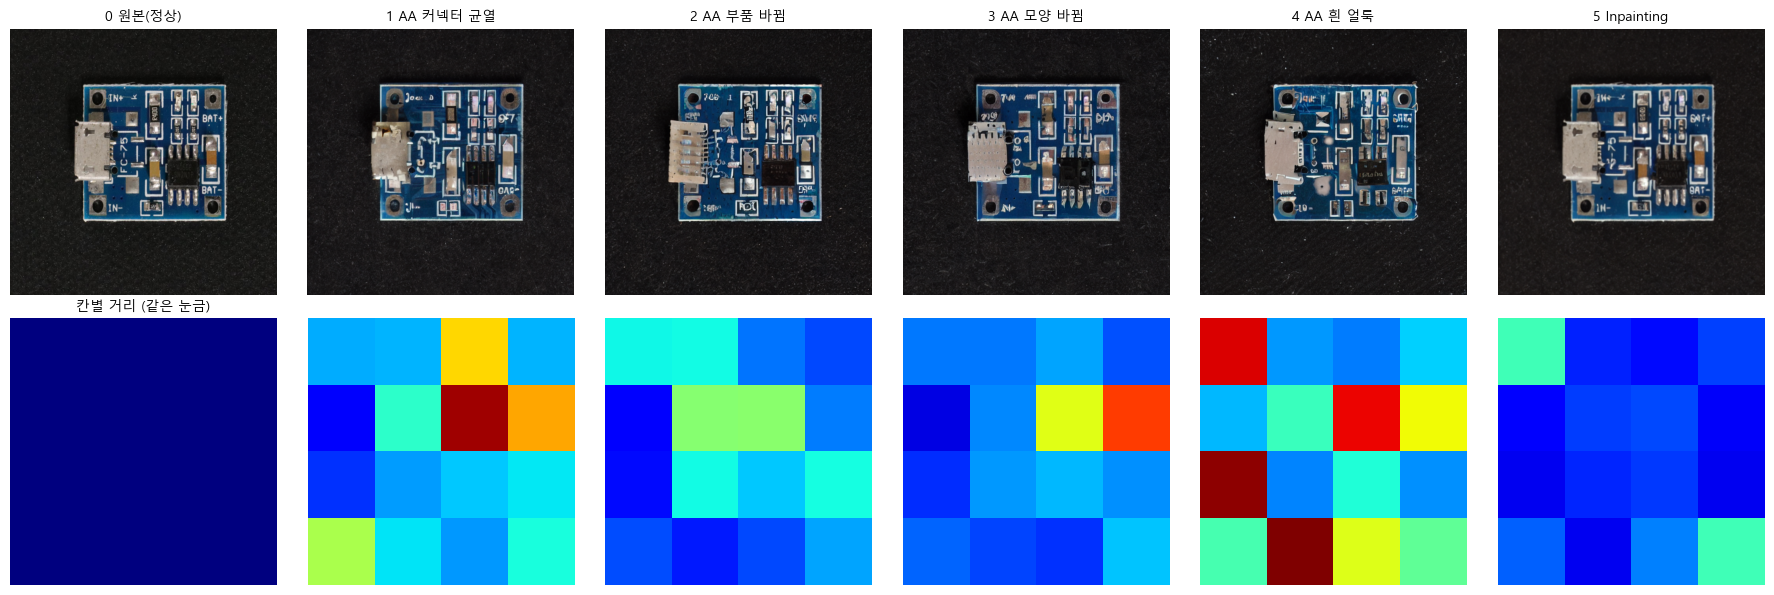

In [8]:
# D3: 원본 정상 사진과 칸별로 비교 (PaDiM처럼 max)
G = 4
def patches(img):
    s = img.size[0] // G
    return [img.crop((c * s, r * s, (c + 1) * s, (r + 1) * s)) for r in range(G) for c in range(G)]


ref = img_emb(patches(images['0_original']))
ref_whole = img_emb([images['0_original']])
rows, maps = [], {}
for k, label in NAMES.items():
    e = img_emb(patches(images[k]))
    dist = (1 - (e * ref).sum(-1)).numpy()            # 같은 자리 칸끼리 1 - 코사인
    maps[label] = dist.reshape(G, G)
    i = int(dist.argmax())
    rows.append({'image': label, 'whole_dist': (1 - img_emb([images[k]]) @ ref_whole.T).item(),
                 'patch_max': dist.max(), 'patch_mean': dist.mean(), 'max_cell(row,col)': (i // G, i % G)})
d3 = pd.DataFrame(rows)
print('[D3] 원본 정상 사진과의 거리 (클수록 정상과 다름)')
print(d3.round(4).to_string(index=False))

fig, axs = plt.subplots(2, 6, figsize=(18, 6))
vmax = max(m.max() for m in maps.values())
for j, (k, label) in enumerate(NAMES.items()):
    axs[0, j].imshow(images[k]); axs[0, j].set_title(label, fontsize=10); axs[0, j].axis('off')
    axs[1, j].imshow(maps[label], cmap='jet', vmin=0, vmax=vmax); axs[1, j].axis('off')
axs[1, 0].set_title('칸별 거리 (같은 눈금)', fontsize=10)
plt.tight_layout()
plt.savefig('images/clip_patch_distance.png', dpi=120)
plt.show()

## 확인과 실험 D 결과 정리

- **작동 확인(A)**: 강아지·자동차·바나나는 모든 사진에서 0. 모델은 제대로 작동한다. 0번 원본 전체는 PCB보다 USB 커넥터(0.908)로 봤다.
- **문장 바꾸기(B·C)**: 커넥터 문장 쌍 3개로 물으니 정상 원본 커넥터의 균열 확률이 0.551 / 0.774 / 0.959로 흔들렸고, 2·3번 쌍에서는 정상이 균열 사진보다 높았다. 예상(올라갈 것)은 반만 맞았다. "1번만 균열로 봤다"는 4쌍 중 2쌍에서만 성립.
- **D1 유사도 원래 값**: 12개 경우 모두 두 문장의 유사도 차이가 0.02 미만. 차이가 클 거라는 예상은 틀렸다. ×100 온도가 작은 차이를 0.7~0.9 확률로 부풀린 것이라 사실상 동전 던지기였다.
- **D2 문장 앙상블**: 클래스당 20문장 평균으로 전체·커넥터 모두 원본 최저, 1번 최고. 더 흔들릴 거라는 예상과 반대로 순위가 안정됐다.
- **D3 정상 사진과 비교**: 사진 전체 거리로는 예상대로 1번이 가장 멀었다(0.081). 16칸 비교는 생성 사진의 위치가 원본과 어긋나서 결함이 아니라 위치 차이를 쟀다. 정렬이 먼저 필요하다.

결론: 이 사진들에 대한 CLIP의 균열 판단은 문장 한 쌍으로는 불안정하고, 앙상블로 안정된다. 생성 결함을 CLIP 점수 하나로 검증하면 안 된다.